In [1]:
!pip install nltk

In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Sample paragraph (5-6 sentences)
text = """
Artificial Intelligence is changing the world.
AI helps people solve complex problems quickly.
Machine learning enables computers to learn from data.
Natural Language Processing helps computers understand human language.
AI is used in healthcare, education, and business.
I find Artificial Intelligence fascinating because it creates useful technology.
"""

# 1. Convert to lowercase and remove punctuation using re
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare Python split() and NLTK word_tokenize()
print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

# 5. Word frequency distribution
freq_dist = FreqDist(filtered_words)
print("\nWord Frequencies:")
for word, frequency in freq_dist.most_common():
    print(word, ":", frequency)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Cleaned Text:
 
artificial intelligence is changing the world
ai helps people solve complex problems quickly
machine learning enables computers to learn from data
natural language processing helps computers understand human language
ai is used in healthcare education and business
i find artificial intelligence fascinating because it creates useful technology


Word Tokens:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'quickly', 'machine', 'learning', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'i', 'find', 'artificial', 'intelligence', 'fascinating', 'because', 'it', 'creates', 'useful', 'technology']

Sentence Tokens:
 ['\nArtificial Intelligence is changing the world.', 'AI helps people solve complex problems quickly.', 'Machine lear

In [3]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Same paragraph from Q1
text = """
Artificial Intelligence is changing the world.
AI helps people solve complex problems quickly.
Machine learning enables computers to learn from data.
Natural Language Processing helps computers understand human language.
AI is used in healthcare, education, and business.
I find Artificial Intelligence fascinating because it creates useful technology.
"""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Stemming using PorterStemmer
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization using WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(w) for w in filtered_words
]
print("\nLemmatized Words:\n", lemmatized_words)

# 5. Compare outputs
print("\nComparison:")
for word, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(word, "-> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'quickly', 'machine', 'learning', 'enables', 'computers', 'to', 'learn', 'from', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'i', 'find', 'artificial', 'intelligence', 'fascinating', 'because', 'it', 'creates', 'useful', 'technology']

After Stopword Removal:
 ['artificial', 'intelligence', 'changing', 'world', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'quickly', 'machine', 'learning', 'enables', 'computers', 'learn', 'data', 'natural', 'language', 'processing', 'helps', 'computers', 'understand', 'human', 'language', 'ai', 'used', 'healthcare', 'education', 'business', 'find', 'artificial', 'intelligence', 'fascinating', 'creates', 'useful', 'technology']

Stemmed Words:
 ['artifici', 'intellig', 'chang'

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts
texts = [
    "Artificial intelligence improves healthcare and diagnosis",
    "Machine learning helps artificial intelligence applications",
    "Healthcare technology uses machine learning for diagnosis"
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

features = tfidf_vectorizer.get_feature_names_out()
print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

# 3. Top 3 keywords from each text
print("\nTop 3 Keywords for Each Text:")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    keywords = [(features[j], round(row[j], 3))
                for j in top_indices]
    print(f"Text {i+1}:", keywords)

Bag of Words Vocabulary:
['and' 'applications' 'artificial' 'diagnosis' 'for' 'healthcare' 'helps'
 'improves' 'intelligence' 'learning' 'machine' 'technology' 'uses']

Bag of Words Matrix:
[[1 0 1 1 0 1 0 1 1 0 0 0 0]
 [0 1 1 0 0 0 1 0 1 1 1 0 0]
 [0 0 0 1 1 1 0 0 0 1 1 1 1]]

TF-IDF Matrix:
[[0.481 0.    0.366 0.366 0.    0.366 0.    0.481 0.366 0.    0.    0.
  0.   ]
 [0.    0.481 0.366 0.    0.    0.    0.481 0.    0.366 0.366 0.366 0.
  0.   ]
 [0.    0.    0.    0.33  0.434 0.33  0.    0.    0.    0.33  0.33  0.434
  0.434]]

Top 3 Keywords for Each Text:
Text 1: [('improves', np.float64(0.481)), ('and', np.float64(0.481)), ('diagnosis', np.float64(0.366))]
Text 2: [('helps', np.float64(0.481)), ('applications', np.float64(0.481)), ('learning', np.float64(0.366))]
Text 3: [('uses', np.float64(0.434)), ('technology', np.float64(0.434)), ('for', np.float64(0.434))]


In [5]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two texts about different technologies
text1 = """
Artificial intelligence uses machine learning to analyze data
and make intelligent decisions.
"""

text2 = """
Blockchain technology stores data in secure distributed ledgers
and improves transaction security.
"""

# 1. Preprocess and tokenize both texts
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text.split()

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Tokens of Text 1:", tokens1)
print("Tokens of Text 2:", tokens2)

# 2(a). Jaccard Similarity using sets
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 3))

# 2(b). Cosine Similarity using TF-IDF
texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine_score = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine_score, 3))

Tokens of Text 1: ['artificial', 'intelligence', 'uses', 'machine', 'learning', 'to', 'analyze', 'data', 'and', 'make', 'intelligent', 'decisions']
Tokens of Text 2: ['blockchain', 'technology', 'stores', 'data', 'in', 'secure', 'distributed', 'ledgers', 'and', 'improves', 'transaction', 'security']

Common Words: {'and', 'data'}
Jaccard Similarity: 0.091
Cosine Similarity: 0.092


In [6]:
!pip install textblob wordcloud matplotlib

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Review 1: This phone is amazing and the battery life is excellent.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review 2: The camera quality is fantastic and I love this phone.
Polarity: 0.45
Subjectivity: 0.75
Sentiment: Positive

Review 3: The product is terrible and the battery drains quickly.
Polarity: -0.333
Subjectivity: 0.75
Sentiment: Negative

Review 4: Very poor quality. I am disappointed with this purchase.
Polarity: -0.635
Subjectivity: 0.765
Sentiment: Negative

Review 5: The phone is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive

Review 6: The design is beautiful and the performance is great.
Polarity: 0.825
Subjectivity: 0.875
Sentiment: Positive


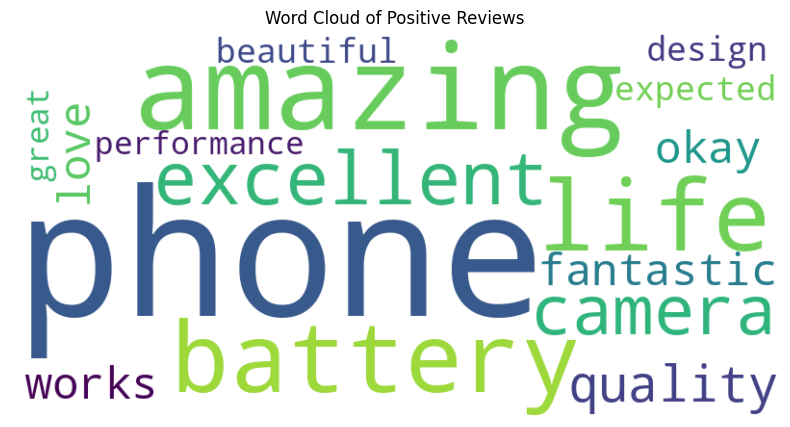

In [7]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

# Download stopwords
nltk.download('stopwords')

# Sample product reviews
reviews = [
    "This phone is amazing and the battery life is excellent.",
    "The camera quality is fantastic and I love this phone.",
    "The product is terrible and the battery drains quickly.",
    "Very poor quality. I am disappointed with this purchase.",
    "The phone is okay and works as expected.",
    "The design is beautiful and the performance is great."
]

positive_reviews = []

# 1. Find polarity and subjectivity
# 2. Classify reviews
for i, review in enumerate(reviews, start=1):
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

    if sentiment == "Positive":
        positive_reviews.append(review)

# 3. Create a word cloud from positive reviews
positive_text = " ".join(positive_reviews)

if positive_text.strip():
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()

In [8]:
!pip install tensorflow

In [9]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training data: approximately 100 words
text = """
Artificial intelligence is transforming the world through technology.
Machine learning helps computers learn from data and solve problems.
Natural language processing enables computers to understand human language.
Deep learning is used in image recognition, speech recognition, and prediction.
Artificial intelligence is useful in healthcare, education, business, and science.
Students can learn artificial intelligence by studying programming and mathematics.
Python is a popular programming language for machine learning and data science.
Data helps intelligent systems identify patterns and make better predictions.
Technology continues to improve as researchers develop new intelligent systems.
Artificial intelligence can automate repetitive tasks and support human decision making.
Learning about artificial intelligence helps students prepare for future careers.
"""

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
print("Total unique words:", total_words)

# Convert text into word sequences
input_sequences = []

for line in text.strip().split("."):
    line = line.strip()
    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequence = token_list[:i + 1]
        input_sequences.append(sequence)

# Pad sequences
max_sequence_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

# Separate inputs and labels
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

# 3. Build the LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# 4. Train the model
model.fit(X, y, epochs=100, verbose=0)

print("Model training completed!")

# 5. Generate new text from a seed word
def generate_text(seed_text, next_words=20):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predicted_probs))

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if not output_word:
            break

        seed_text += " " + output_word

    return seed_text

# Generate 2-3 lines of text
print("\nGenerated Text:")
print(generate_text("artificial intelligence", 25))

Total unique words: 71
Input shape: (100, 11)
Output shape: (100,)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model training completed!

Generated Text:
artificial intelligence intelligence intelligence the world through technology technology decision making making making making making making making making making making making decision making making making making making
